In [1]:
from typing import TypedDict, Literal
from langgraph.constants import START, END
from langgraph.graph import StateGraph
from langgraph.types import Command
from IPython.display import Image, display

class CustomState(TypedDict):
    score: int
    result: str

def node_score(state: CustomState) -> Command[Literal["node_fail", "node_pass"]]:
    score = int(input("请输入分数: "))
    goto = "node_fail" if score < 60 else "node_pass"
    return Command(
        goto=goto,
        update={"score": score}
    )

def node_fail(state: CustomState):
    return {"result": "不及格"}

def node_pass(state: CustomState):
    return {"result": "及格"}


graph_builder = StateGraph(CustomState)

graph_builder.add_node("node_score", node_score)
graph_builder.add_node("node_fail", node_fail)
graph_builder.add_node("node_pass", node_pass)

graph_builder.add_edge(START, "node_score")
graph_builder.add_edge("node_fail", END)
graph_builder.add_edge("node_pass", END)

graph = graph_builder.compile()

result = graph.invoke({"score": 0})

print(result)


{'score': 18, 'result': '不及格'}


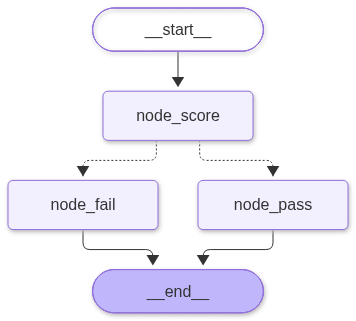

In [2]:
display(Image(graph.get_graph().draw_mermaid_png()))